In [1]:
import pandas as pd
import numpy as np
import os

In [2]:
# 데이터 파일 경로
CSV_PATH = './file/lotto.csv'
EXCEL_PATH = './file/lotto.xlsx'

print("현재 작업 폴더:", os.getcwd())
print("CSV 파일 존재:", os.path.exists(CSV_PATH))
print("Excel 파일 존재:", os.path.exists(EXCEL_PATH))

현재 작업 폴더: c:\workspace\process\aix_process1012\p1108
CSV 파일 존재: True
Excel 파일 존재: True


In [3]:
# CSV 데이터 불러오기
df = pd.read_csv(CSV_PATH, encoding='utf-8-sig')

# 기본 데이터 확인
print("전체 데이터:", len(df))
print("전체 열 개수:", len(df.columns))
print("최신 회차:", df['회차'].max())
print("가장 오래된 회차:", df['회차'].min())

print("\n[최신 회차 5개]")
display(df.head())

print("\n[오래된 회차 5개]")
display(df.tail())

전체 데이터: 1249
전체 열 개수: 8
최신 회차: 1249
가장 오래된 회차: 1

[최신 회차 5개]


,회차,번호1,번호2,번호3,번호4,번호5,번호6,보너스
0,1249,2,11,16,25,34,35,14
1,1248,16,18,27,36,38,42,22
2,1247,8,14,21,22,42,45,24
3,1246,16,22,23,24,27,28,6
4,1245,4,5,25,28,32,42,12



[오래된 회차 5개]


,회차,번호1,번호2,번호3,번호4,번호5,번호6,보너스
1244,5,16,24,29,40,41,42,3
1245,4,14,27,30,31,40,42,2
1246,3,11,16,19,21,27,31,30
1247,2,9,13,21,25,32,42,2
1248,1,10,23,29,33,37,40,16


In [4]:
# 1. 회차 중복 검사
duplicate_count = df['회차'].duplicated().sum()

# 2. 당첨번호 결측치 검사
number_cols = [
    '번호1', '번호2', '번호3',
    '번호4', '번호5', '번호6', '보너스'
]

missing_count = df[number_cols].isna().sum().sum()

# 3. 번호 범위 검사
invalid_count = (
    (df[number_cols] < 1) |
    (df[number_cols] > 45)
).sum().sum()

print("회차 중복 개수:", duplicate_count)
print("당첨번호 결측치 개수:", missing_count)
print("번호 범위 오류 개수:", invalid_count)

회차 중복 개수: 0
당첨번호 결측치 개수: 0
번호 범위 오류 개수: 0


In [5]:
# 회차별 당첨번호 6개 중복 검사

main_cols = [
    '번호1', '번호2', '번호3',
    '번호4', '번호5', '번호6'
]

duplicate_rows = df[
    df[main_cols].apply(
        lambda row: row.nunique() != 6,
        axis=1
    )
]

print("당첨번호 중복 회차 수:", len(duplicate_rows))

if len(duplicate_rows) == 0:
    print("전체 회차 당첨번호 6개 중복 없음")
else:
    display(duplicate_rows)

당첨번호 중복 회차 수: 0
전체 회차 당첨번호 6개 중복 없음


In [6]:
# 번호별 출현 빈도 계산

main_cols = [
    '번호1', '번호2', '번호3',
    '번호4', '번호5', '번호6'
]

# 6개 당첨번호를 하나로 합치기
all_numbers = df[main_cols].values.flatten()

# 번호별 출현 횟수
frequency = (
    pd.Series(all_numbers)
    .value_counts()
    .reindex(range(1, 46), fill_value=0)
    .sort_index()
)

# 데이터프레임으로 변환
freq_df = frequency.reset_index()
freq_df.columns = ['번호', '출현횟수']

In [7]:
print("번호 종류:", len(freq_df))
print("전체 출현 횟수:", freq_df['출현횟수'].sum())

print("\n출현 빈도 상위 10개")
display(
    freq_df.sort_values(
        '출현횟수',
        ascending=False
    ).head(10)
)

print("\n출현 빈도 하위 10개")
display(
    freq_df.sort_values(
        '출현횟수',
        ascending=True
    ).head(10)
)

번호 종류: 45
전체 출현 횟수: 7494

출현 빈도 상위 10개


,번호,출현횟수
33,34,188
12,13,184
26,27,183
17,18,181
11,12,180
44,45,176
32,33,175
37,38,175
39,40,174
36,37,174



출현 빈도 하위 10개


,번호,출현횟수
8,9,137
31,32,147
21,22,148
22,23,150
40,41,151
4,5,154
24,25,155
28,29,156
29,30,158
1,2,158


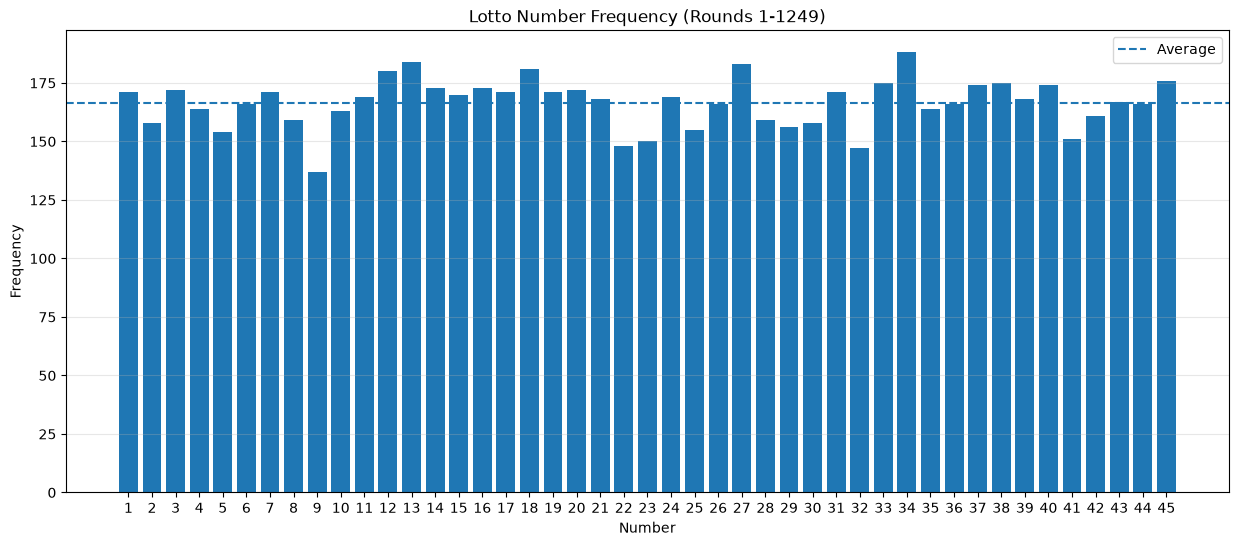

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.bar(
    freq_df['번호'],
    freq_df['출현횟수']
)

plt.axhline(
    freq_df['출현횟수'].mean(),
    linestyle='--',
    label='Average'
)

plt.title('Lotto Number Frequency (Rounds 1-1249)')
plt.xlabel('Number')
plt.ylabel('Frequency')
plt.xticks(range(1, 46))
plt.legend()
plt.grid(axis='y', alpha=0.3)

In [9]:
# 번호별 평균 출현 횟수 계산

average_count = freq_df['출현횟수'].mean()

print("전체 번호 평균 출현 횟수:", round(average_count, 2))
print("최고 출현 횟수:", freq_df['출현횟수'].max())
print("최저 출현 횟수:", freq_df['출현횟수'].min())

전체 번호 평균 출현 횟수: 166.53
최고 출현 횟수: 188
최저 출현 횟수: 137


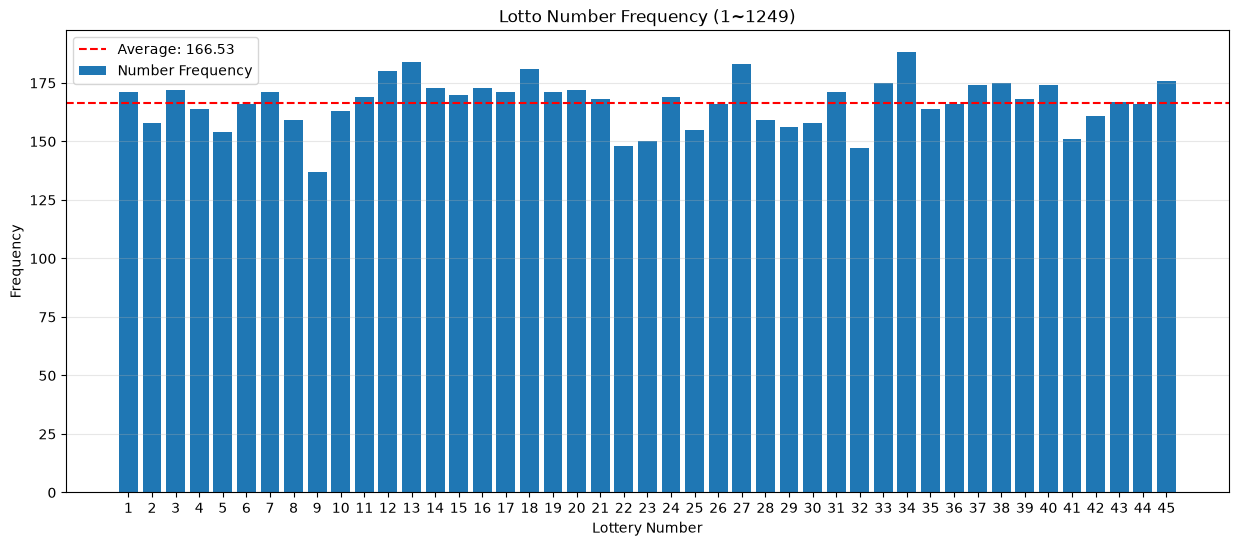

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.bar(
    freq_df['번호'],
    freq_df['출현횟수'],
    label='Number Frequency'
)

plt.axhline(
    y=average_count,
    color='red',
    linestyle='--',
    label=f'Average: {average_count:.2f}'
)

plt.xticks(range(1, 46))
plt.xlabel('Lottery Number')
plt.ylabel('Frequency')
plt.title('Lotto Number Frequency (1~1249)')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

In [11]:
# 평균 대비 출현 횟수 차이 계산

freq_df['평균대비차이'] = (
    freq_df['출현횟수'] - average_count
)

display(freq_df)

,번호,출현횟수,평균대비차이
0,1,171,4.466667
1,2,158,-8.533333
2,3,172,5.466667
3,4,164,-2.533333
4,5,154,-12.533333
5,6,166,-0.533333
6,7,171,4.466667
7,8,159,-7.533333
8,9,137,-29.533333
9,10,163,-3.533333


In [12]:
# 행 인덱스를 제거하고 실제 번호만 표시

display(
    freq_df.style
    .format({
        '평균대비차이': '{:+.2f}'
    })
    .hide(axis='index')
)

번호,출현횟수,평균대비차이
1,171,+4.47
2,158,-8.53
3,172,+5.47
4,164,-2.53
5,154,-12.53
6,166,-0.53
7,171,+4.47
8,159,-7.53
9,137,-29.53
10,163,-3.53


In [13]:
# 평균보다 많이 출현한 번호
above_avg = freq_df[
    freq_df['평균대비차이'] > 0
]

# 평균보다 적게 출현한 번호
below_avg = freq_df[
    freq_df['평균대비차이'] < 0
]

print("평균보다 많이 출현한 번호:", len(above_avg), "개")
display(above_avg)

print("평균보다 적게 출현한 번호:", len(below_avg), "개")
display(below_avg)

평균보다 많이 출현한 번호: 25 개


,번호,출현횟수,평균대비차이
0,1,171,4.466667
2,3,172,5.466667
6,7,171,4.466667
10,11,169,2.466667
11,12,180,13.466667
12,13,184,17.466667
13,14,173,6.466667
14,15,170,3.466667
15,16,173,6.466667
16,17,171,4.466667


평균보다 적게 출현한 번호: 20 개


,번호,출현횟수,평균대비차이
1,2,158,-8.533333
3,4,164,-2.533333
4,5,154,-12.533333
5,6,166,-0.533333
7,8,159,-7.533333
8,9,137,-29.533333
9,10,163,-3.533333
21,22,148,-18.533333
22,23,150,-16.533333
24,25,155,-11.533333


In [14]:
# 출현 횟수 기준 내림차순 정렬

rank_df = freq_df.sort_values(
    by='출현횟수',
    ascending=False
).reset_index(drop=True)

# 순위 추가
rank_df.insert(
    0,
    '순위',
    range(1, len(rank_df) + 1)
)

display(rank_df)

,순위,번호,출현횟수,평균대비차이
0,1,34,188,21.466667
1,2,13,184,17.466667
2,3,27,183,16.466667
3,4,18,181,14.466667
4,5,12,180,13.466667
5,6,45,176,9.466667
6,7,33,175,8.466667
7,8,38,175,8.466667
8,9,40,174,7.466667
9,10,37,174,7.466667


In [15]:
display(
    rank_df.style
    .format({
        '평균대비차이': '{:+.2f}'
    })
    .hide(axis='index')
)

순위,번호,출현횟수,평균대비차이
1,34,188,+21.47
2,13,184,+17.47
3,27,183,+16.47
4,18,181,+14.47
5,12,180,+13.47
6,45,176,+9.47
7,33,175,+8.47
8,38,175,+8.47
9,40,174,+7.47
10,37,174,+7.47


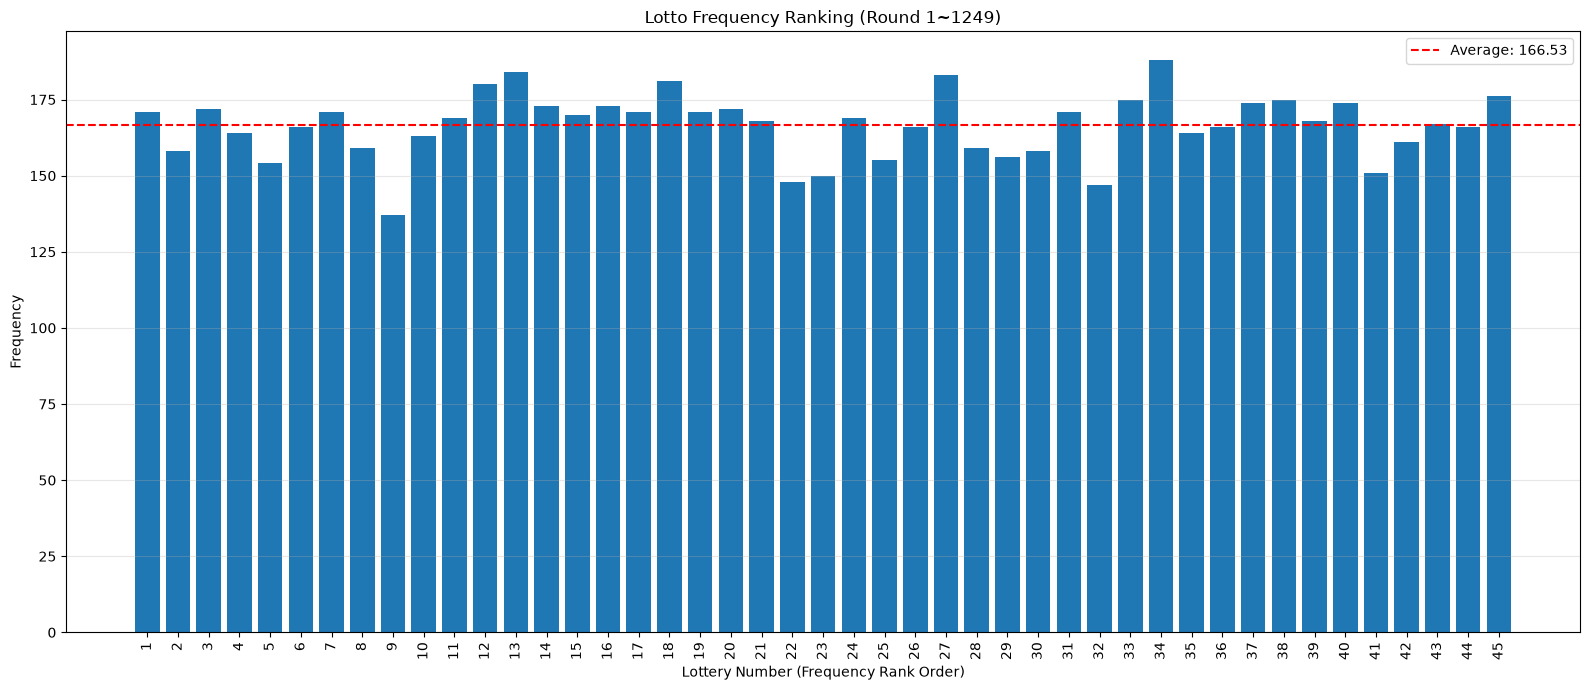

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 7))

plt.bar(
    rank_df['번호'],
    rank_df['출현횟수']
)

plt.axhline(
    y=average_count,
    color='red',
    linestyle='--',
    label=f'Average: {average_count:.2f}'
)

plt.xticks(
    rank_df['번호'],
    rotation=90
)

plt.xlabel('Lottery Number (Frequency Rank Order)')
plt.ylabel('Frequency')
plt.title('Lotto Frequency Ranking (Round 1~1249)')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
# 최근 10회 데이터 추출

recent_10 = df.sort_values(
    by='회차',
    ascending=False
).head(10)

print("최근 10회 데이터")
display(recent_10)

최근 10회 데이터


,회차,번호1,번호2,번호3,번호4,번호5,번호6,보너스
0,1249,2,11,16,25,34,35,14
1,1248,16,18,27,36,38,42,22
2,1247,8,14,21,22,42,45,24
3,1246,16,22,23,24,27,28,6
4,1245,4,5,25,28,32,42,12
5,1244,1,13,18,26,34,38,25
6,1243,9,18,24,38,43,44,35
7,1242,2,4,10,16,31,41,9
8,1241,7,13,16,23,24,43,9
9,1240,11,13,19,20,31,44,27


In [18]:
# 최근 10회 당첨번호 6개만 추출

recent_numbers = recent_10[main_cols].values.flatten()

# 번호별 출현 횟수 계산
recent_10_frequency = (
    pd.Series(recent_numbers)
    .value_counts()
    .reindex(range(1, 46), fill_value=0)
    .sort_index()
)

# 데이터프레임으로 변환
recent_10_df = recent_10_frequency.reset_index()

recent_10_df.columns = ['번호', '출현횟수']

display(recent_10_df)

,번호,출현횟수
0,1,1
1,2,2
2,3,0
3,4,2
4,5,1
5,6,0
6,7,1
7,8,1
8,9,1
9,10,1


In [19]:
display(
    recent_10_df.style
    .hide(axis='index')
)

번호,출현횟수
1,1
2,2
3,0
4,2
5,1
6,0
7,1
8,1
9,1
10,1


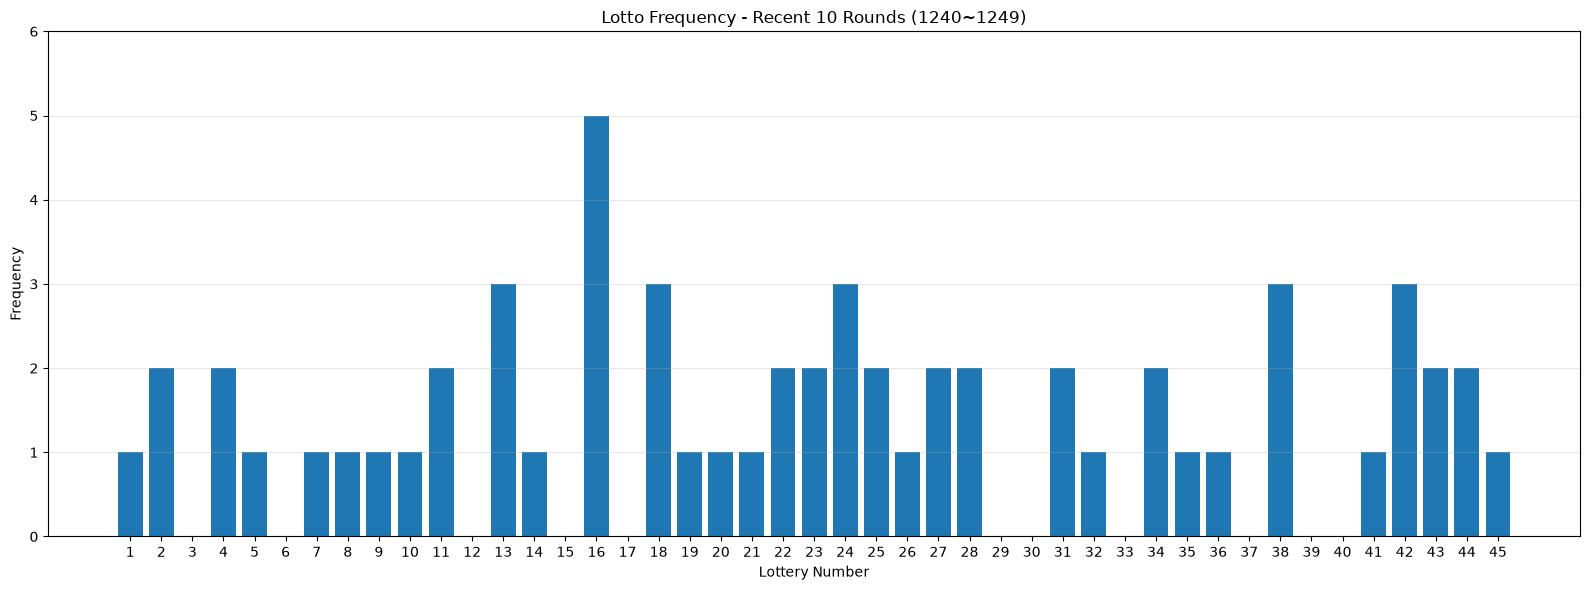

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.bar(
    recent_10_df['번호'],
    recent_10_df['출현횟수']
)

plt.xlabel('Lottery Number')
plt.ylabel('Frequency')
plt.title('Lotto Frequency - Recent 10 Rounds (1240~1249)')

plt.xticks(range(1, 46))
plt.yticks(range(0, 7))

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
print("전체 번호 개수:", len(recent_10_df))
print("출현 횟수 합계:", recent_10_df['출현횟수'].sum())
print("출현 횟수 0인 번호:")
print(
    recent_10_df.loc[
        recent_10_df['출현횟수'] == 0,
        '번호'
    ].tolist()
)

전체 번호 개수: 45
출현 횟수 합계: 60
출현 횟수 0인 번호:
[3, 6, 12, 15, 17, 29, 30, 33, 37, 39, 40]


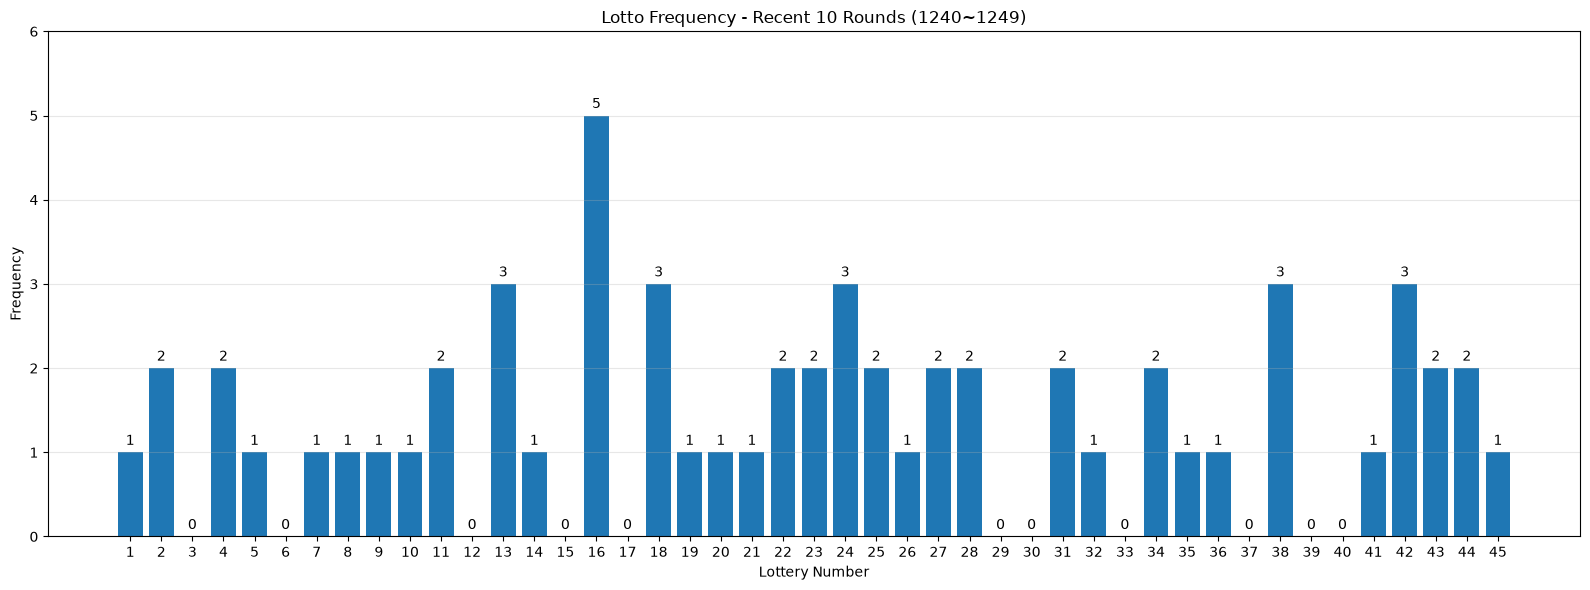

In [22]:
plt.figure(figsize=(16, 6))

bars = plt.bar(
    recent_10_df['번호'],
    recent_10_df['출현횟수']
)

plt.bar_label(bars, padding=3)

plt.xlabel('Lottery Number')
plt.ylabel('Frequency')
plt.title('Lotto Frequency - Recent 10 Rounds (1240~1249)')

plt.xticks(range(1, 46))
plt.yticks(range(0, 7))
plt.ylim(0, 6)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# 최근 30회 데이터 추출

recent_30 = df.sort_values(
    by='회차',
    ascending=False
).head(30)

print("최근 30회 데이터")
display(recent_30)

최근 30회 데이터


,회차,번호1,번호2,번호3,번호4,번호5,번호6,보너스
0,1249,2,11,16,25,34,35,14
1,1248,16,18,27,36,38,42,22
2,1247,8,14,21,22,42,45,24
3,1246,16,22,23,24,27,28,6
4,1245,4,5,25,28,32,42,12
5,1244,1,13,18,26,34,38,25
6,1243,9,18,24,38,43,44,35
7,1242,2,4,10,16,31,41,9
8,1241,7,13,16,23,24,43,9
9,1240,11,13,19,20,31,44,27


In [24]:
# 최근 30회 당첨번호 6개 추출

recent_30_numbers = recent_30[main_cols].values.flatten()

# 번호별 출현 횟수 계산
recent_30_frequency = (
    pd.Series(recent_30_numbers)
    .value_counts()
    .reindex(range(1, 46), fill_value=0)
    .sort_index()
)

# 데이터프레임으로 변환
recent_30_df = recent_30_frequency.reset_index()

recent_30_df.columns = ['번호', '출현횟수']

print("번호 종류:", len(recent_30_df))
print("전체 출현 횟수:", recent_30_df['출현횟수'].sum())

display(
    recent_30_df.style
    .hide(axis='index')
)

번호 종류: 45
전체 출현 횟수: 180


번호,출현횟수
1,3
2,5
3,1
4,5
5,1
6,3
7,3
8,3
9,4
10,2


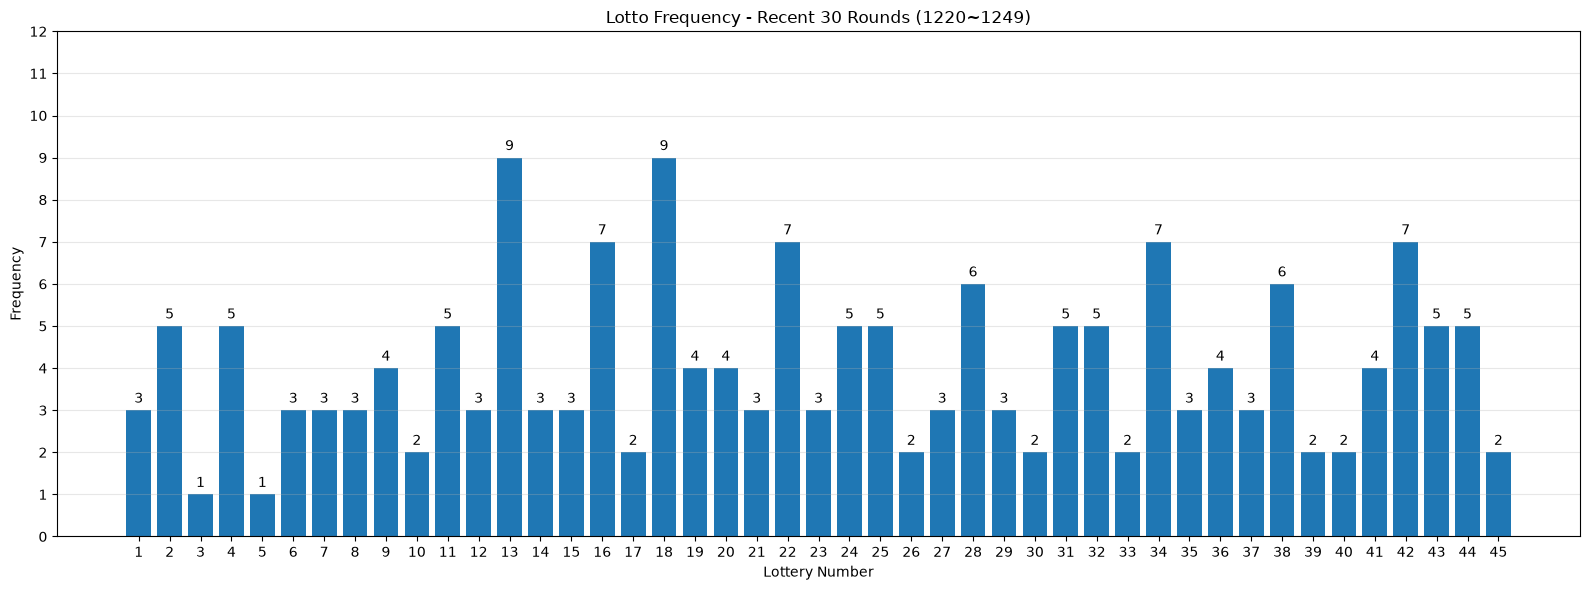

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

bars = plt.bar(
    recent_30_df['번호'],
    recent_30_df['출현횟수']
)

plt.bar_label(bars, padding=3)

plt.xlabel('Lottery Number')
plt.ylabel('Frequency')
plt.title('Lotto Frequency - Recent 30 Rounds (1220~1249)')

plt.xticks(range(1, 46))
plt.yticks(range(0, 13))
plt.ylim(0, 12)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
# 최근 50회 데이터 추출

recent_50 = df.sort_values(
    by='회차',
    ascending=False
).head(50)

print("최근 50회 데이터")
print("데이터 행 개수:", len(recent_50))
print("최신 회차:", recent_50['회차'].max())
print("가장 오래된 회차:", recent_50['회차'].min())

display(recent_50)

최근 50회 데이터
데이터 행 개수: 50
최신 회차: 1249
가장 오래된 회차: 1200


,회차,번호1,번호2,번호3,번호4,번호5,번호6,보너스
0,1249,2,11,16,25,34,35,14
1,1248,16,18,27,36,38,42,22
2,1247,8,14,21,22,42,45,24
3,1246,16,22,23,24,27,28,6
4,1245,4,5,25,28,32,42,12
5,1244,1,13,18,26,34,38,25
6,1243,9,18,24,38,43,44,35
7,1242,2,4,10,16,31,41,9
8,1241,7,13,16,23,24,43,9
9,1240,11,13,19,20,31,44,27


In [27]:
# 최근 50회 당첨번호 빈도 계산

recent_50_numbers = recent_50[main_cols].values.flatten()

recent_50_frequency = (
    pd.Series(recent_50_numbers)
    .value_counts()
    .reindex(range(1, 46), fill_value=0)
    .sort_index()
)

recent_50_df = recent_50_frequency.reset_index()
recent_50_df.columns = ['번호', '출현횟수']

print("번호 종류:", len(recent_50_df))
print("전체 출현 횟수:", recent_50_df['출현횟수'].sum())

display(recent_50_df.style.hide(axis='index'))

번호 종류: 45
전체 출현 횟수: 300


번호,출현횟수
1,8
2,8
3,5
4,7
5,4
6,5
7,5
8,6
9,6
10,6


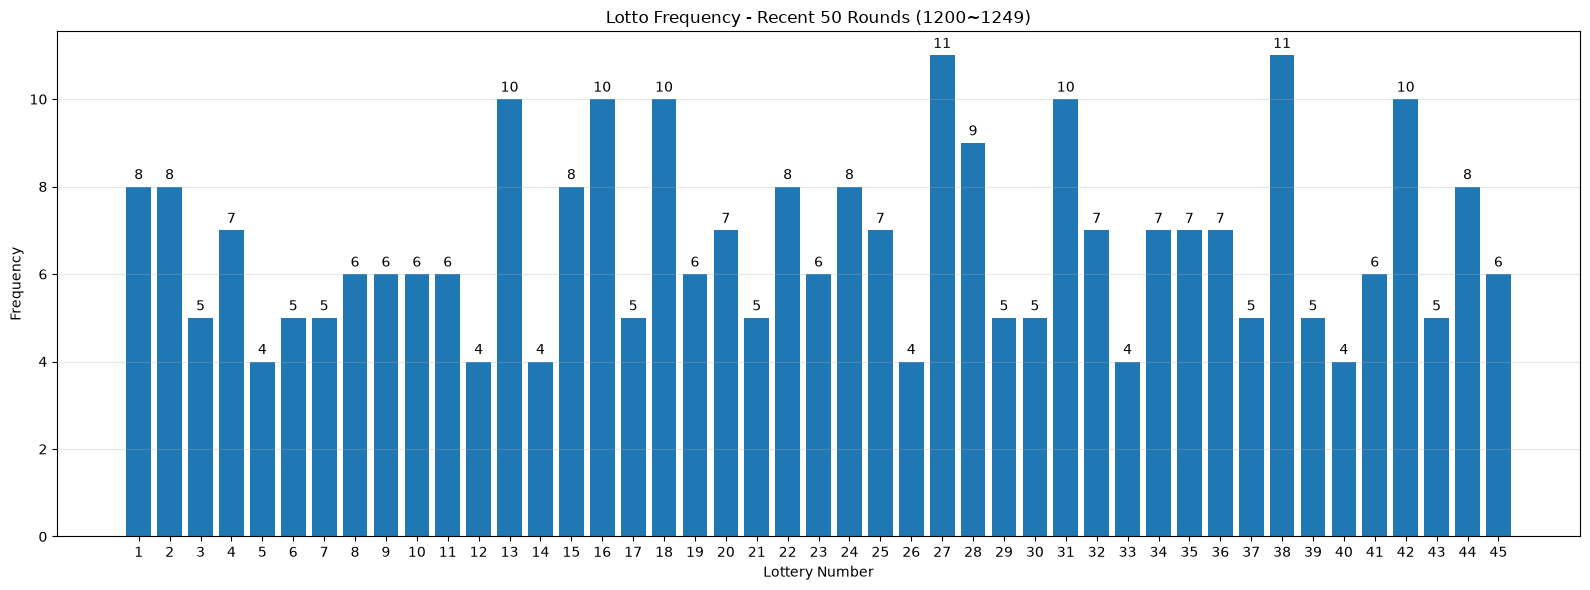

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

bars = plt.bar(
    recent_50_df['번호'],
    recent_50_df['출현횟수']
)

plt.bar_label(bars, padding=3)

plt.xlabel('Lottery Number')
plt.ylabel('Frequency')
plt.title('Lotto Frequency - Recent 50 Rounds (1200~1249)')

plt.xticks(range(1, 46))
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [29]:
# 기간별 출현 횟수 비교표 만들기

compare_df = (
    recent_10_df.rename(
        columns={'출현횟수': '최근10회'}
    )
    .merge(
        recent_30_df.rename(
            columns={'출현횟수': '최근30회'}
        ),
        on='번호'
    )
    .merge(
        recent_50_df.rename(
            columns={'출현횟수': '최근50회'}
        ),
        on='번호'
    )
)

display(compare_df.style.hide(axis='index'))

번호,최근10회,최근30회,최근50회
1,1,3,8
2,2,5,8
3,0,1,5
4,2,5,7
5,1,1,4
6,0,3,5
7,1,3,5
8,1,3,6
9,1,4,6
10,1,2,6


In [30]:
# 기간별 출현 비율 계산

compare_df['최근10회 비율(%)'] = (
    compare_df['최근10회'] / 60 * 100
).round(2)

compare_df['최근30회 비율(%)'] = (
    compare_df['최근30회'] / 180 * 100
).round(2)

compare_df['최근50회 비율(%)'] = (
    compare_df['최근50회'] / 300 * 100
).round(2)

display(compare_df.style.hide(axis='index'))

번호,최근10회,최근30회,최근50회,최근10회 비율(%),최근30회 비율(%),최근50회 비율(%)
1,1,3,8,1.670000,1.670000,2.670000
2,2,5,8,3.330000,2.780000,2.670000
3,0,1,5,0.000000,0.560000,1.670000
4,2,5,7,3.330000,2.780000,2.330000
5,1,1,4,1.670000,0.560000,1.330000
6,0,3,5,0.000000,1.670000,1.670000
7,1,3,5,1.670000,1.670000,1.670000
8,1,3,6,1.670000,1.670000,2.000000
9,1,4,6,1.670000,2.220000,2.000000
10,1,2,6,1.670000,1.110000,2.000000


In [31]:
# 출현 비율을 소수점 둘째 자리까지 표시

display(
    compare_df.style
    .format({
        '최근10회 비율(%)': '{:.2f}',
        '최근30회 비율(%)': '{:.2f}',
        '최근50회 비율(%)': '{:.2f}'
    })
    .hide(axis='index')
)

번호,최근10회,최근30회,최근50회,최근10회 비율(%),최근30회 비율(%),최근50회 비율(%)
1,1,3,8,1.67,1.67,2.67
2,2,5,8,3.33,2.78,2.67
3,0,1,5,0.00,0.56,1.67
4,2,5,7,3.33,2.78,2.33
5,1,1,4,1.67,0.56,1.33
6,0,3,5,0.00,1.67,1.67
7,1,3,5,1.67,1.67,1.67
8,1,3,6,1.67,1.67,2.00
9,1,4,6,1.67,2.22,2.00
10,1,2,6,1.67,1.11,2.00


In [32]:
# 기간별 출현 비율 합계 확인

print(
    "최근 10회 비율 합계:",
    compare_df['최근10회 비율(%)'].sum()
)

print(
    "최근 30회 비율 합계:",
    compare_df['최근30회 비율(%)'].sum()
)

print(
    "최근 50회 비율 합계:",
    compare_df['최근50회 비율(%)'].sum()
)

최근 10회 비율 합계: 100.01
최근 30회 비율 합계: 100.05000000000001
최근 50회 비율 합계: 100.00000000000001
